<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_06_KNN_dan_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 6.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

### Praktikum 6.2 Import Dataset

In [2]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

### Praktikum 6.3 Preprocessing (Scaling untuk KNN)

In [3]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Catatan: Naive Bayes tidak memerlukan scaling, namun KNN sangat sensitif terhadap skala fitur.

### Praktikum 6.4 Training Model

In [4]:
knn = KNeighborsClassifier(n_neighbors=5, weights="distance")
knn.fit(X_train_scaled, y_train)

nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

### Praktikum 6.5 Evaluasi

In [5]:
acc_knn = accuracy_score(y_test, knn.predict(X_test_scaled))
acc_nb = accuracy_score(y_test, nb.predict(X_test))
print(f"Akurasi KNN (k=5, weighted): {acc_knn:.3f}")
print(f"Akurasi Gaussian Naive Bayes: {acc_nb:.3f}")

Akurasi KNN (k=5, weighted): 0.972
Akurasi Gaussian Naive Bayes: 0.972


### Praktikum 6.6 Visualisasi (Pengaruh Nilai k)

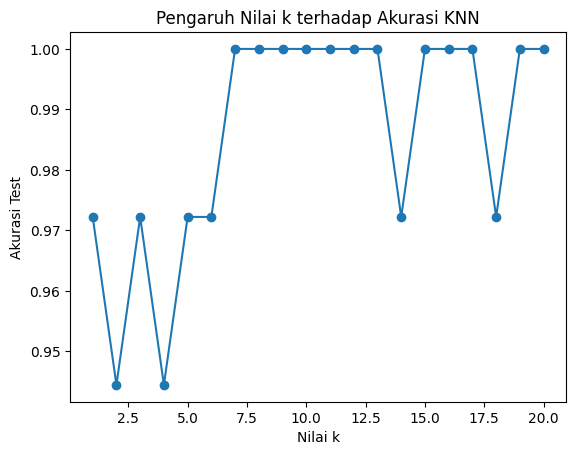

In [6]:
akurasi_k = []
nilai_k = range(1, 21)
for k in nilai_k:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    akurasi_k.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(nilai_k, akurasi_k, marker='o')
plt.xlabel("Nilai k"); plt.ylabel("Akurasi Test")
plt.title("Pengaruh Nilai k terhadap Akurasi KNN")
plt.show()

## Bagian B — Latihan Praktikum

In [7]:
import time
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline

bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, bc.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=42)

def ukur_waktu(buat_model, X_tr, y_tr, X_te, ulang=50):
    t_fit, t_pred = [], []
    for _ in range(ulang):
        m = buat_model()
        t0 = time.perf_counter(); m.fit(X_tr, y_tr); t1 = time.perf_counter()
        m.predict(X_te); t2 = time.perf_counter()
        t_fit.append(t1 - t0); t_pred.append(t2 - t1)
    return np.mean(t_fit) * 1000, np.mean(t_pred) * 1000   # ms

model_knn = lambda: Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))])
model_nb = lambda: GaussianNB()

baris = []
for nama, buat in [("KNN (k=5, + scaling)", model_knn), ("Gaussian Naive Bayes", model_nb)]:
    fit_ms, pred_ms = ukur_waktu(buat, Xb_train, yb_train, Xb_test)
    m = buat().fit(Xb_train, yb_train)
    baris.append({"Model": nama, "Akurasi test": accuracy_score(yb_test, m.predict(Xb_test)),
                  "Waktu latih (ms)": fit_ms, "Waktu prediksi (ms)": pred_ms})
hasil_waktu = pd.DataFrame(baris).set_index("Model")
hasil_waktu.round(3)

,Akurasi test,Waktu latih (ms),Waktu prediksi (ms)
Model,,,
"KNN (k=5, + scaling)",0.956,7.523,8.438
Gaussian Naive Bayes,0.939,2.660,1.648


In [8]:
# Pelengkap: akurasi lebih andal dengan 5-Fold CV
from sklearn.model_selection import cross_val_score, StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for nama, buat in [("KNN (k=5, + scaling)", model_knn), ("Gaussian Naive Bayes", model_nb)]:
    s = cross_val_score(buat(), Xb, yb, cv=skf)
    print(f"{nama}: akurasi CV = {s.mean():.3f} +/- {s.std():.3f}")

KNN (k=5, + scaling): akurasi CV = 0.963 +/- 0.018
Gaussian Naive Bayes: akurasi CV = 0.939 +/- 0.023


### Praktikum 2 — Klasifikasi Teks dengan Multinomial Naive Bayes (Praktikum 6.7)

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

teks = ["dapatkan diskon gratis sekarang",
        "rapat tim jam 10 pagi",
        "menangkan hadiah gratis klik disini",
        "laporan keuangan bulan ini",
        "diskon spesial hari ini",
        "jadwal kuliah minggu depan"]
label = [1, 0, 1, 0, 1, 0]   # 1 = spam, 0 = bukan spam

vectorizer = CountVectorizer()
X_teks = vectorizer.fit_transform(teks)
model = MultinomialNB(alpha=1.0)   # alpha = parameter Laplace Smoothing
model.fit(X_teks, label)

teks_baru = ["diskon gratis hari ini"]
prediksi = model.predict(vectorizer.transform(teks_baru))
print("Prediksi:", "Spam" if prediksi[0] == 1 else "Bukan Spam")
print("Probabilitas [bukan spam, spam]:", model.predict_proba(vectorizer.transform(teks_baru)).round(3))

Prediksi: Spam
Probabilitas [bukan spam, spam]: [[0.053 0.947]]


In [11]:
# Tambahan: pengaruh Laplace Smoothing (alpha) pada kata yang tidak pernah muncul di salah satu kelas
uji = ["gratis rapat", "kuliah gratis klik"]
for a in [1e-10, 1.0]:
    m = MultinomialNB(alpha=a).fit(X_teks, label)
    for t in uji:
        p = m.predict_proba(vectorizer.transform([t]))[0]
        print(f"alpha={a:<7} | '{t}' -> P(bukan spam)={p[0]:.3f}, P(spam)={p[1]:.3f}")
print("\nKosakata:", list(vectorizer.get_feature_names_out()))

alpha=1e-10   | 'gratis rapat' -> P(bukan spam)=0.333, P(spam)=0.667
alpha=1e-10   | 'kuliah gratis klik' -> P(bukan spam)=0.000, P(spam)=1.000
alpha=1.0     | 'gratis rapat' -> P(bukan spam)=0.400, P(spam)=0.600
alpha=1.0     | 'kuliah gratis klik' -> P(bukan spam)=0.250, P(spam)=0.750

Kosakata: ['10', 'bulan', 'dapatkan', 'depan', 'disini', 'diskon', 'gratis', 'hadiah', 'hari', 'ini', 'jadwal', 'jam', 'keuangan', 'klik', 'kuliah', 'laporan', 'menangkan', 'minggu', 'pagi', 'rapat', 'sekarang', 'spesial', 'tim']
